In [114]:
import csv

# Define o conteúdo de transacoes.csv (Pode ser alterado para testes)
csv_content = """id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-20,CLI001,debito,abc,valor nao numerico,teste
4,2026-02-03,,debito,200.00,Sem cliente,teste
5,2026-02-14,CLI003,credito,15000.00,Transferência suspeita,transferencia
6,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
7,2026-03-01,CLI001,credito,3500.00,Salário março,salario
8,2026-03-10,CLI003,debito,99.90,Streaming,assinatura
9,2026-01-25,CLI004,debito,50.00,Livro,compra
10,2026-02-05,CLI005,credito,2500.00,Adiantamento,salario
A,2026-02-06,CLI005,credito,2500.00,id invalido,teste
,2026-02-06,CLI005,credito,250.00,id nulo,teste
11,2026-03-15,CLI004,debito,120.00,Restaurante,alimentacao
12,2026-01-01,CLI001,credito,12000.00,Bônus anual,salario
13,2026-02-20,CLI002,debito,75.00,Cafeteria,alimentacao
14,2026-03-25,CLI005,credito,500.00,Reembolso,outros
15,2026-01-08,CLI003,debito,25.00,Estacionamento,transporte
16,2026-02-10,CLI001,debito,1000.00,Aluguel,moradia
17,2026-03-05,CLI002,credito,7000.00,Venda,outros
18,2026-04-01,CLI006,credito,100.00,Presente,outros
19,2026-04-10,CLI006,debito,20.00,Revista,lazer
20,2026-04-15,CLI001,credito,10000.00,Investimento,investimento
21,16-04-2026,CLI001,credito,1000.00,data incorreta,teste
22,,CLI001,credito,1000.00,data nula,teste
23,2026-04-16,CLI001,teste,1000.00,tipo invalido,teste
24,2026-04-16,CLI001,debito,-1.00,valor negativo,teste
"""

# Escreve o arquivo transacoes.csv para a próxima etapa de leitura
try:
    with open('transacoes.csv', 'w', newline='', encoding='utf-8') as f:
        f.write(csv_content)
    print("Arquivo 'transacoes.csv' criado com sucesso.")
except IOError as e:
    print(f"Erro ao criar o arquivo 'transacoes.csv': {e}")

Arquivo 'transacoes.csv' criado com sucesso.


In [115]:
import csv
import datetime

# Constante para transações suspeitas
LIMITE_SUSPEITO = 10000.00
# Constante para exibição das linhas inválidas
EXIBE_DEBUG_MSG = True

def ler_transacoes(filepath):
    """
    Lê o arquivo CSV de transações, valida cada linha e retorna uma lista de transações válidas.
    """
    transacoes_validas = []
    transacoes_invalidas_count = 0
    total_linhas_lidas = 0

    try:
        with open(filepath, mode='r', newline='', encoding='utf-8') as file:
            reader = csv.DictReader(file)
            for row in reader:
                total_linhas_lidas += 1
                # Valida a linha e adiciona à lista de válidas se passar
                valid, cleaned_transaction = validar_transacao(row)
                if valid:
                    transacoes_validas.append(cleaned_transaction)
                else:
                    transacoes_invalidas_count += 1

    except FileNotFoundError:
        print(f"Erro: O arquivo '{filepath}' não foi encontrado.")
        return [], 0, 0, 0
    except Exception as e:
        print(f"Ocorreu um erro inesperado ao ler o arquivo: {e}")
        return [], 0, 0, 0


    if EXIBE_DEBUG_MSG: print("=" * 72)
    print(f"Total de linhas lidas: {total_linhas_lidas}")
    print(f"Linhas válidas: {len(transacoes_validas)}")
    print(f"Linhas inválidas: {transacoes_invalidas_count}")

    return transacoes_validas, total_linhas_lidas, len(transacoes_validas), transacoes_invalidas_count

def validar_transacao(transacao_bruta):
    """
    Valida uma única linha de transação bruta e retorna (True, transacao_limpa) se válida,
    ou (False, None) se inválida.
    """
    # Campos esperados e seus tipos
    campos = ['id', 'data', 'cliente_id', 'tipo', 'valor', 'descricao', 'categoria']

    # Verifica se todos os campos esperados estão presentes
    if not all(campo in transacao_bruta for campo in campos):
        if EXIBE_DEBUG_MSG: print(f"DEBUG: Linha ignorada - campos faltando: {transacao_bruta}")
        return False, None

    transacao_limpa = {}

    # 1. Validar ID (inteiro e não vazio)
    try:
        transacao_limpa['id'] = int(transacao_bruta['id'])
        if transacao_limpa['id'] <= 0: # IDs devem ser positivos
            if EXIBE_DEBUG_MSG: print(f"DEBUG: ID inválido: {transacao_bruta['id']}")
            return False, None
    except (ValueError, KeyError):
        if EXIBE_DEBUG_MSG: print(f"DEBUG: ID não numérico ou vazio: {transacao_bruta['id']}")
        return False, None

    # 2. Validar data (formato AAAA-MM-DD)
    try:
        transacao_limpa['data'] = datetime.datetime.strptime(transacao_bruta['data'], '%Y-%m-%d').date()
    except (ValueError, KeyError):
        if EXIBE_DEBUG_MSG: print(f"DEBUG: Data inválida: {transacao_bruta['data']}")
        return False, None

    # 3. Validar cliente_id (não pode ser vazio)
    transacao_limpa['cliente_id'] = transacao_bruta['cliente_id'].strip()
    if not transacao_limpa['cliente_id']:
        if EXIBE_DEBUG_MSG: print(f"DEBUG: Cliente ID vazio: {transacao_bruta['cliente_id']}")
        return False, None

    # 4. Validar tipo (credito ou debito)
    transacao_limpa['tipo'] = transacao_bruta['tipo'].lower()
    if transacao_limpa['tipo'] not in ['credito', 'debito']:
        if EXIBE_DEBUG_MSG: print(f"DEBUG: Tipo inválido: {transacao_bruta['tipo']}")
        return False, None

    # 5. Validar valor (numérico e maior que 0)
    try:
        transacao_limpa['valor'] = float(transacao_bruta['valor'])
        if transacao_limpa['valor'] <= 0:
            if EXIBE_DEBUG_MSG:
                print(f"DEBUG: Valor não positivo: {transacao_bruta['valor']}")
            return False, None
    except (ValueError, KeyError):
        if EXIBE_DEBUG_MSG: print(f"DEBUG: Valor não numérico ou vazio: {transacao_bruta['valor']}")
        return False, None

    # 6. Descrição e Categoria podem ser vazias ou ter qualquer texto
    transacao_limpa['descricao'] = transacao_bruta['descricao'].strip()
    transacao_limpa['categoria'] = transacao_bruta['categoria'].strip()

    return True, transacao_limpa

# Exemplo de uso (descomente para testar)
# if __name__ == "__main__":
#     filepath = 'transacoes.csv'
#     transacoes_validas, total_lidas, validas_count, invalidas_count = ler_transacoes(filepath)
#     print("\nTransações Válidas (primeiras 5):")
#     for i, t in enumerate(transacoes_validas[:5]):
#         print(t)
#     print(f"Total de transações válidas: {validas_count}")
#     print(f"Total de transações inválidas: {invalidas_count}")


In [116]:
import datetime

def gerar_relatorio(transacoes_validas):
    """
    Processa a lista de transações válidas para gerar um relatório mensal
    e identificar transações suspeitas.
    """
    resumo_mensal = {}
    transacoes_suspeitas = []
    data_mais_antiga = None
    data_mais_recente = None

    for transacao in transacoes_validas:
        # Atualiza as datas mais antiga e mais recente
        if data_mais_antiga is None or transacao['data'] < data_mais_antiga:
            data_mais_antiga = transacao['data']
        if data_mais_recente is None or transacao['data'] > data_mais_recente:
            data_mais_recente = transacao['data']

        # Extrai o mês no formato AAAA-MM
        mes_ano = transacao['data'].strftime('%Y-%m')

        # Inicializa o mês se ainda não existir no resumo
        if mes_ano not in resumo_mensal:
            resumo_mensal[mes_ano] = {
                'quantidade': 0,
                'total_credito': 0.0,
                'total_debito': 0.0,
                'saldo': 0.0,
                'media': 0.0,
                'maior_valor': float('-inf'),
                'menor_valor': float('inf')
            }

        # Atualiza métricas mensais
        resumo_mensal[mes_ano]['quantidade'] += 1
        if transacao['tipo'] == 'credito':
            resumo_mensal[mes_ano]['total_credito'] += transacao['valor']
        else:
            resumo_mensal[mes_ano]['total_debito'] += transacao['valor']

        if transacao['valor'] > resumo_mensal[mes_ano]['maior_valor']:
            resumo_mensal[mes_ano]['maior_valor'] = transacao['valor']
        if transacao['valor'] < resumo_mensal[mes_ano]['menor_valor']:
            resumo_mensal[mes_ano]['menor_valor'] = transacao['valor']

        # Identifica transações suspeitas
        if transacao['valor'] > LIMITE_SUSPEITO:
            transacoes_suspeitas.append({
                'id': transacao['id'],
                'cliente_id': transacao['cliente_id'],
                'data': transacao['data'].strftime('%Y-%m-%d'),
                'valor': transacao['valor']
            })

    # Calcula saldo e média para cada mês
    for mes_ano, dados in resumo_mensal.items():
        dados['saldo'] = dados['total_credito'] - dados['total_debito']
        if dados['quantidade'] > 0:
            dados['media'] = (dados['total_credito'] + dados['total_debito']) / dados['quantidade']
        else:
            dados['media'] = 0.0 # Caso não haja transações para o mês

    return {
        'resumo_mensal': resumo_mensal,
        'transacoes_suspeitas': transacoes_suspeitas,
        'data_mais_antiga': data_mais_antiga,
        'data_mais_recente': data_mais_recente
    }

# Exemplo de uso (descomente para testar)
# if __name__ == "__main__":
#     filepath = 'transacoes.csv'
#     transacoes_validas, _, _, _ = ler_transacoes(filepath)
#     relatorio = gerar_relatorio(transacoes_validas)
#     print("\nRelatório Mensal:", relatorio['resumo_mensal'])
#     print("\nTransações Suspeitas:", relatorio['transacoes_suspeitas'])
#     print("\nData Mais Antiga:", relatorio['data_mais_antiga'])
#     print("\nData Mais Recente:", relatorio['data_mais_recente'])


In [117]:
import json
import datetime

def salvar_json(relatorio_data, total_validas, total_invalidas, filepath='relatorio.json'):
    """
    Salva o relatório final em um arquivo JSON.
    """
    # Certificar que as datas são strings para serialização JSON
    resumo_mensal_serializavel = {}
    for mes, dados in relatorio_data['resumo_mensal'].items():
        resumo_mensal_serializavel[mes] = {
            'quantidade': dados['quantidade'],
            'total_credito': round(dados['total_credito'], 2),
            'total_debito': round(dados['total_debito'], 2),
            'saldo': round(dados['saldo'], 2),
            'media': round(dados['media'], 2),
            'maior_valor': round(dados['maior_valor'], 2),
            'menor_valor': round(dados['menor_valor'], 2)
        }

    # Prepara os dados para o JSON
    dados_json = {
        "gerado_em": datetime.date.today().strftime("%Y-%m-%d"),
        "total_transacoes_validas": total_validas,
        "total_transacoes_invalidas": total_invalidas,
        "resumo_mensal": resumo_mensal_serializavel,
        "transacoes_suspeitas": relatorio_data['transacoes_suspeitas']
    }

    try:
        with open(filepath, 'w', encoding='utf-8') as f:
            json.dump(dados_json, f, ensure_ascii=False, indent=2)
        print(f"Relatório salvo com sucesso em '{filepath}'.")
    except IOError as e:
        print(f"Erro ao salvar o arquivo JSON '{filepath}': {e}")

# Exemplo de uso (descomente para testar)
# if __name__ == "__main__":
#     filepath_csv = 'transacoes.csv'
#     transacoes_validas, total_lidas, validas_count, invalidas_count = ler_transacoes(filepath_csv)
#     relatorio_gerado = gerar_relatorio(transacoes_validas)
#     salvar_json(relatorio_gerado, validas_count, invalidas_count)


In [118]:
from google.colab import files

# Baixa o JSON para sua máquina local
files.download('relatorio.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [119]:
import datetime

def formatar_moeda(valor):
    """
    Formata um valor numérico para o padrão monetário brasileiro (R$ X.XXX,XX).
    """
    # Arredonda para 2 casas decimais e formata como string com separador de milhares e vírgula decimal
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

def exibir_relatorio(relatorio_data, total_lidas, total_validas, total_invalidas):
    """
    Formata e imprime o relatório no terminal.
    """
    print("\n" + "=" * 25 + " RELATÓRIO CLEARBANK " + "=" * 25)

    # Período analisado
    data_mais_antiga = relatorio_data['data_mais_antiga']
    data_mais_recente = relatorio_data['data_mais_recente']

    if data_mais_antiga and data_mais_recente:
        print(f"Período analisado: {data_mais_antiga.strftime('%d/%m/%Y')} a {data_mais_recente.strftime('%d/%m/%Y')}")
        print(f"Total de dias no período: {(data_mais_recente - data_mais_antiga).days + 1} dias")
    else:
        print("Período analisado: N/A")

    print(f"Total de linhas lidas do arquivo: {total_lidas}")
    print(f"Transações válidas processadas: {total_validas}")
    print(f"Transações inválidas descartadas: {total_invalidas}")
    print("=" * 72)

    # Resumo Mensal
    print("\n" + "=" * 25 + " RESUMO MENSAL " + "=" * 26)
    if not relatorio_data['resumo_mensal']:
        print("Nenhum dado de transação válida para gerar o resumo mensal.")
    else:
        # Ordena os meses
        meses_ordenados = sorted(relatorio_data['resumo_mensal'].keys())
        for mes_ano in meses_ordenados:
            dados = relatorio_data['resumo_mensal'][mes_ano]
            print(f"\nMês: {mes_ano}")
            print(f"  Transações: {dados['quantidade']}")
            print(f"  Total crédito: {formatar_moeda(dados['total_credito'])}")
            print(f"  Total débito:  {formatar_moeda(dados['total_debito'])}")
            print(f"  Saldo:         {formatar_moeda(dados['saldo'])}")
            if dados['quantidade'] > 0:
                print(f"  Média:         {formatar_moeda(dados['media'])}")
                print(f"  Maior valor:   {formatar_moeda(dados['maior_valor'])}")
                print(f"  Menor valor:   {formatar_moeda(dados['menor_valor'])}")
            else:
                print("  Média:         N/A")
                print("  Maior valor:   N/A")
                print("  Menor valor:   N/A")

    print("=" * 72)

    # Transações Suspeitas
    print("\n" + "=" * 22 + " TRANSAÇÕES SUSPEITAS " + "=" * 22)
    if not relatorio_data['transacoes_suspeitas']:
        print("Nenhuma transação suspeita encontrada.")
    else:
        for t in relatorio_data['transacoes_suspeitas']:
            print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data']} | Valor: {formatar_moeda(t['valor'])}")
    print("=" * 72 + "\n")


# Exemplo de uso (descomente para testar)
# if __name__ == "__main__":
#     filepath_csv = 'transacoes.csv'
#     transacoes_validas, total_lidas, validas_count, invalidas_count = ler_transacoes(filepath_csv)
#     relatorio_gerado = gerar_relatorio(transacoes_validas)
#     exibir_relatorio(relatorio_gerado, total_lidas, validas_count, invalidas_count)


In [120]:
# Célula de Execução Principal
if __name__ == "__main__":
    filepath_csv = 'transacoes.csv'

    # 1. Ler e validar transações
    print("Iniciando leitura e validação das transações...")
    transacoes_validas, total_lidas, validas_count, invalidas_count = ler_transacoes(filepath_csv)
    print("Leitura e validação concluídas.")

    if not transacoes_validas:
        print("\nNão há transações válidas para gerar o relatório. Encerrando.")
    else:
        # 2. Gerar relatório mensal e identificar suspeitas
        print("\nGerando relatório financeiro...")
        relatorio_gerado = gerar_relatorio(transacoes_validas)
        print("Relatório financeiro gerado.")

        # 3. Salvar relatório em JSON
        print("\nSalvando relatório em formato JSON...")
        salvar_json(relatorio_gerado, validas_count, invalidas_count, filepath='relatorio.json')
        print("Relatório JSON salvo.")

        # 4. Exibir relatório no terminal
        print("\nExibindo relatório no terminal...")
        exibir_relatorio(relatorio_gerado, total_lidas, validas_count, invalidas_count)
        print("Relatório exibido. Análise concluída.")


Iniciando leitura e validação das transações...
DEBUG: Valor não numérico ou vazio: abc
DEBUG: Cliente ID vazio: 
DEBUG: ID não numérico ou vazio: A
DEBUG: ID não numérico ou vazio: 
DEBUG: Data inválida: 16-04-2026
DEBUG: Data inválida: 
DEBUG: Tipo inválido: teste
DEBUG: Valor não positivo: -1.00
Total de linhas lidas: 26
Linhas válidas: 18
Linhas inválidas: 8
Leitura e validação concluídas.

Gerando relatório financeiro...
Relatório financeiro gerado.

Salvando relatório em formato JSON...
Relatório salvo com sucesso em 'relatorio.json'.
Relatório JSON salvo.

Exibindo relatório no terminal...

========================= RELATÓRIO CLEARBANK =========================
Período analisado: 01/01/2026 a 15/04/2026
Total de dias no período: 105 dias
Total de linhas lidas do arquivo: 26
Transações válidas processadas: 18
Transações inválidas descartadas: 8

========================= RESUMO MENSAL ==========================

Mês: 2026-01
  Transações: 5
  Total crédito: R$ 15.500,00
  Total d

## Requisito Opcional 1: Análise com Pandas

Vamos implementar uma versão alternativa da leitura e do agrupamento utilizando a biblioteca `pandas`. Compararemos os resultados para garantir que são consistentes com a solução nativa.

In [121]:
import pandas as pd

def analise_com_pandas(filepath, limite_suspeito=LIMITE_SUSPEITO):
    """
    Realiza a análise de transações utilizando a biblioteca pandas.
    """
    try:
        # 1. Leitura do arquivo CSV com pandas
        df = pd.read_csv(filepath)
        print("Arquivo lido com pandas.")

        # 2. Validação e limpeza dos dados
        # Converte 'id' para inteiro, forçando NaN para erros
        df['id'] = pd.to_numeric(df['id'], errors='coerce')
        # Converte 'data' para datetime, forçando NaT para erros
        df['data'] = pd.to_datetime(df['data'], errors='coerce')
        # Converte 'valor' para float, forçando NaN para erros
        df['valor'] = pd.to_numeric(df['valor'], errors='coerce')

        # Remove linhas com campos essenciais inválidos ou vazios
        # id > 0, data não NaT, cliente_id não vazio, tipo válido, valor > 0
        df_limpo = df.dropna(subset=['id', 'data', 'cliente_id', 'tipo', 'valor']).copy()
        df_limpo = df_limpo[df_limpo['id'] > 0]
        df_limpo = df_limpo[df_limpo['valor'] > 0]
        df_limpo['tipo'] = df_limpo['tipo'].str.lower()
        df_limpo = df_limpo[df_limpo['tipo'].isin(['credito', 'debito'])]

        total_linhas_lidas_pd = len(df)
        validas_count_pd = len(df_limpo)
        invalidas_count_pd = total_linhas_lidas_pd - validas_count_pd

        print(f"Total de linhas lidas (pandas): {total_linhas_lidas_pd}")
        print(f"Linhas válidas (pandas): {validas_count_pd}")
        print(f"Linhas inválidas (pandas): {invalidas_count_pd}")

        if df_limpo.empty:
            return None, None

        # 3. Agrupamento mensal e métricas
        df_limpo['mes_ano'] = df_limpo['data'].dt.strftime('%Y-%m')

        resumo_mensal_pd = df_limpo.groupby('mes_ano').agg(
            quantidade=('id', 'count'),
            total_credito=('valor', lambda x: x[df_limpo['tipo'] == 'credito'].sum()),
            total_debito=('valor', lambda x: x[df_limpo['tipo'] == 'debito'].sum()),
            maior_valor=('valor', 'max'),
            menor_valor=('valor', 'min')
        ).reset_index()

        resumo_mensal_pd['saldo'] = resumo_mensal_pd['total_credito'] - resumo_mensal_pd['total_debito']
        resumo_mensal_pd['media'] = (resumo_mensal_pd['total_credito'] + resumo_mensal_pd['total_debito']) / resumo_mensal_pd['quantidade']

        # Garante que 'total_credito' e 'total_debito' sejam 0 se não houver transações do tipo no mês
        # (groupby agg com lambda já deveria tratar isso, mas é uma boa verificação)
        resumo_mensal_pd['total_credito'] = resumo_mensal_pd['total_credito'].fillna(0)
        resumo_mensal_pd['total_debito'] = resumo_mensal_pd['total_debito'].fillna(0)

        # 4. Identificação de transações suspeitas
        transacoes_suspeitas_pd = df_limpo[df_limpo['valor'] > limite_suspeito][['id', 'cliente_id', 'data', 'valor']].copy()
        transacoes_suspeitas_pd['data'] = transacoes_suspeitas_pd['data'].dt.strftime('%Y-%m-%d')

        # Converter para formato de dicionário para comparação ou uso posterior
        resumo_mensal_dict = resumo_mensal_pd.set_index('mes_ano').to_dict(orient='index')
        transacoes_suspeitas_list = transacoes_suspeitas_pd.to_dict(orient='records')

        print("\n--- Resumo Mensal (Pandas) ---")
        display(resumo_mensal_pd)
        print("\n--- Transações Suspeitas (Pandas) ---")
        display(transacoes_suspeitas_pd)

        return resumo_mensal_dict, transacoes_suspeitas_list

    except FileNotFoundError:
        print(f"Erro (pandas): O arquivo '{filepath}' não foi encontrado.")
        return None, None
    except Exception as e:
        print(f"Ocorreu um erro inesperado na análise com pandas: {e}")
        return None, None

# Executa a análise com pandas
print("\nIniciando análise com Pandas...")
resumo_pandas, suspeitas_pandas = analise_com_pandas(filepath_csv)

# Comparação com o relatório gerado pela solução nativa (opcional)
if resumo_pandas and relatorio_gerado['resumo_mensal']:
    print("\n--- Comparação de Resultados (Resumo Mensal) ---")
    for mes in sorted(relatorio_gerado['resumo_mensal'].keys()):
        print(f"\n{mes}:")
        nativo = relatorio_gerado['resumo_mensal'].get(mes)
        pandas = resumo_pandas.get(mes)

        if nativo and pandas:
            print(f"  Qtd. Nativo: {nativo['quantidade']}, Qtd. Pandas: {int(pandas['quantidade'])}")
            print(f"  Créd. Nativo: {nativo['total_credito']:.2f}, Créd. Pandas: {pandas['total_credito']:.2f}")
            print(f"  Déb. Nativo: {nativo['total_debito']:.2f}, Déb. Pandas: {pandas['total_debito']:.2f}")
            print(f"  Saldo Nativo: {nativo['saldo']:.2f}, Saldo Pandas: {pandas['saldo']:.2f}")
            print(f"  Média Nativo: {nativo['media']:.2f}, Média Pandas: {pandas['media']:.2f}")
        else:
            print(f"  Dados divergentes ou ausentes para o mês {mes}")



Iniciando análise com Pandas...
Arquivo lido com pandas.
Total de linhas lidas (pandas): 26
Linhas válidas (pandas): 18
Linhas inválidas (pandas): 8

--- Resumo Mensal (Pandas) ---


,mes_ano,quantidade,total_credito,total_debito,maior_valor,menor_valor,saldo,media
0,2026-01,5,15500.0,255.5,12000.0,25.0,15244.5,3151.100000
1,2026-02,5,17500.0,1395.0,15000.0,75.0,16105.0,3779.000000
2,2026-03,5,11000.0,219.9,7000.0,99.9,10780.1,2243.980000
3,2026-04,3,10100.0,20.0,10000.0,20.0,10080.0,3373.333333



--- Transações Suspeitas (Pandas) ---


,id,cliente_id,data,valor
4,5.0,CLI003,2026-02-14,15000.0
13,12.0,CLI001,2026-01-01,12000.0



--- Comparação de Resultados (Resumo Mensal) ---

2026-01:
  Qtd. Nativo: 5, Qtd. Pandas: 5
  Créd. Nativo: 15500.00, Créd. Pandas: 15500.00
  Déb. Nativo: 255.50, Déb. Pandas: 255.50
  Saldo Nativo: 15244.50, Saldo Pandas: 15244.50
  Média Nativo: 3151.10, Média Pandas: 3151.10

2026-02:
  Qtd. Nativo: 5, Qtd. Pandas: 5
  Créd. Nativo: 17500.00, Créd. Pandas: 17500.00
  Déb. Nativo: 1395.00, Déb. Pandas: 1395.00
  Saldo Nativo: 16105.00, Saldo Pandas: 16105.00
  Média Nativo: 3779.00, Média Pandas: 3779.00

2026-03:
  Qtd. Nativo: 5, Qtd. Pandas: 5
  Créd. Nativo: 11000.00, Créd. Pandas: 11000.00
  Déb. Nativo: 219.90, Déb. Pandas: 219.90
  Saldo Nativo: 10780.10, Saldo Pandas: 10780.10
  Média Nativo: 2243.98, Média Pandas: 2243.98

2026-04:
  Qtd. Nativo: 3, Qtd. Pandas: 3
  Créd. Nativo: 10100.00, Créd. Pandas: 10100.00
  Déb. Nativo: 20.00, Déb. Pandas: 20.00
  Saldo Nativo: 10080.00, Saldo Pandas: 10080.00
  Média Nativo: 3373.33, Média Pandas: 3373.33


## Requisito Opcional 2: Visualização com Matplotlib

Vamos gerar um gráfico de barras empilhadas mostrando o total de crédito e débito por mês e salvá-lo como `grafico.png`.


Gerando visualização com Matplotlib...
Gráfico salvo como 'grafico.png'.


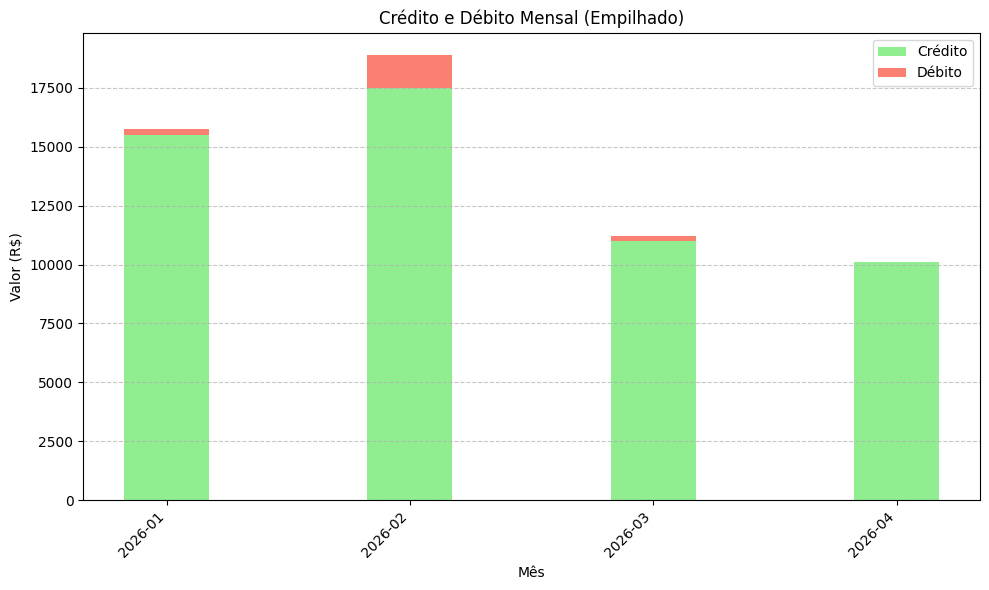

In [122]:
import matplotlib.pyplot as plt

def plot_monthly_credit_debit(resumo_mensal_data, filename='grafico.png'):
    """
    Gera um gráfico de barras empilhadas para crédito e débito mensal.
    """
    if not resumo_mensal_data:
        print("Nenhum dado mensal para gerar o gráfico.")
        return

    # Ordenar os meses cronologicamente
    meses = sorted(resumo_mensal_data.keys())
    creditos = [resumo_mensal_data[mes]['total_credito'] for mes in meses]
    debitos = [resumo_mensal_data[mes]['total_debito'] for mes in meses]

    fig, ax = plt.subplots(figsize=(10, 6))

    bar_width = 0.35
    index = range(len(meses))

    bar1 = ax.bar(index, creditos, bar_width, label='Crédito', color='lightgreen')
    bar2 = ax.bar(index, debitos, bar_width, bottom=creditos, label='Débito', color='salmon') # Empilhado

    ax.set_xlabel('Mês')
    ax.set_ylabel('Valor (R$)')
    ax.set_title('Crédito e Débito Mensal (Empilhado)')
    ax.set_xticks(index)
    ax.set_xticklabels(meses, rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(filename)
    print(f"Gráfico salvo como '{filename}'.")
    plt.show()

# Gera o gráfico usando os dados do relatório nativo
print("\nGerando visualização com Matplotlib...")
plot_monthly_credit_debit(relatorio_gerado['resumo_mensal'])


In [123]:
from google.colab import files

# Baixa o arquivo grafico.png para sua máquina local
files.download('grafico.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>